# Ejercicio Integrador - Clustering

Incluye validación del número de clusters para evitar errores en DBSCAN.

> **Nota:** dataset ficticio de 8 clientes, creado para practicar la técnica. Sirve para ilustrar el procedimiento, no para sacar conclusiones generalizables.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score

sns.set(style="whitegrid")

In [2]:
df = pd.DataFrame({
    "Cliente": [1, 2, 3, 4, 5, 6, 7, 8],
    "Compras_Mensuales": [5, 15, 10, 20, 7, 18, 12, 6],
    "Gasto_Promedio": [30000, 60000, 70000, 80000, 45000, 85000, 72000, 48000],
    "Frecuencia_Compra": ["Alta", "Media", "Baja", "Alta", "Media", "Baja", "Alta", "Media"]
})
df

   Cliente  Compras_Mensuales  Gasto_Promedio Frecuencia_Compra
0        1                  5           30000              Alta
1        2                 15           60000             Media
2        3                 10           70000              Baja
3        4                 20           80000              Alta
4        5                  7           45000             Media
5        6                 18           85000              Baja
6        7                 12           72000              Alta
7        8                  6           48000             Media

In [3]:
le = LabelEncoder()
df["Frecuencia_Compra_Num"] = le.fit_transform(df["Frecuencia_Compra"])

scaler = MinMaxScaler()
df[["Compras_Mensuales", "Gasto_Promedio"]] = scaler.fit_transform(df[["Compras_Mensuales", "Gasto_Promedio"]])
X = df[["Compras_Mensuales", "Gasto_Promedio", "Frecuencia_Compra_Num"]]
df

   Cliente  Compras_Mensuales  Gasto_Promedio Frecuencia_Compra  \
0        1           0.000000        0.000000              Alta   
1        2           0.666667        0.545455             Media   
2        3           0.333333        0.727273              Baja   
3        4           1.000000        0.909091              Alta   
4        5           0.133333        0.272727             Media   
5        6           0.866667        1.000000              Baja   
6        7           0.466667        0.763636              Alta   
7        8           0.066667        0.327273             Media   

   Frecuencia_Compra_Num  
0                      0  
1                      2  
2                      1  
3                      0  
4                      2  
5                      1  
6                      0  
7                      2  

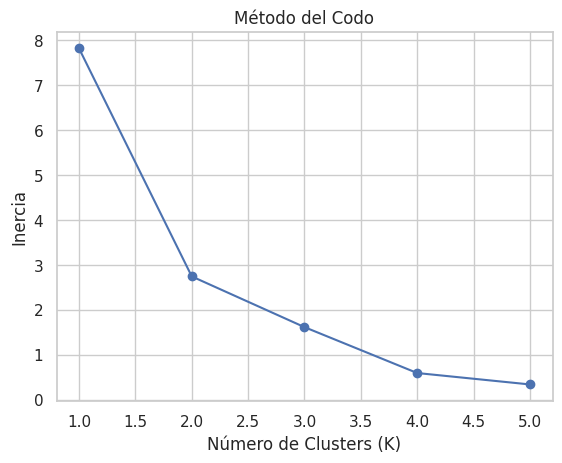

In [4]:
inertia = []
for k in range(1, 6):
    model = KMeans(n_clusters=k, random_state=42)
    model.fit(X)
    inertia.append(model.inertia_)

plt.plot(range(1, 6), inertia, marker="o")
plt.title("Método del Codo")
plt.xlabel("Número de Clusters (K)")
plt.ylabel("Inercia")
plt.show()

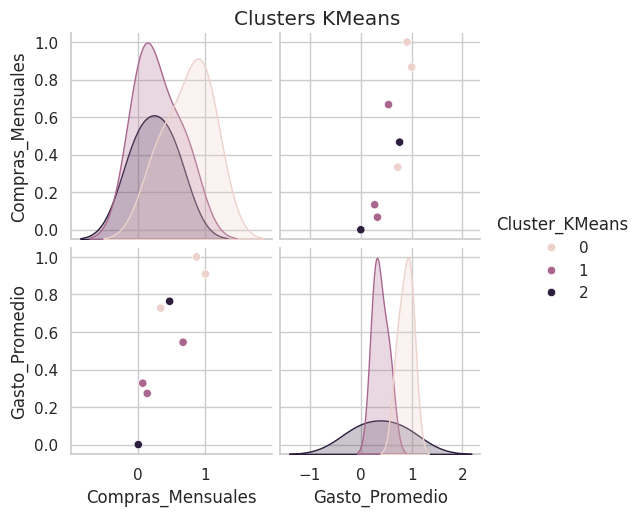

In [5]:
kmeans = KMeans(n_clusters=3, random_state=42)
df["Cluster_KMeans"] = kmeans.fit_predict(X)

sns.pairplot(df, hue="Cluster_KMeans", vars=["Compras_Mensuales", "Gasto_Promedio"])
plt.suptitle("Clusters KMeans", y=1.02)
plt.show()

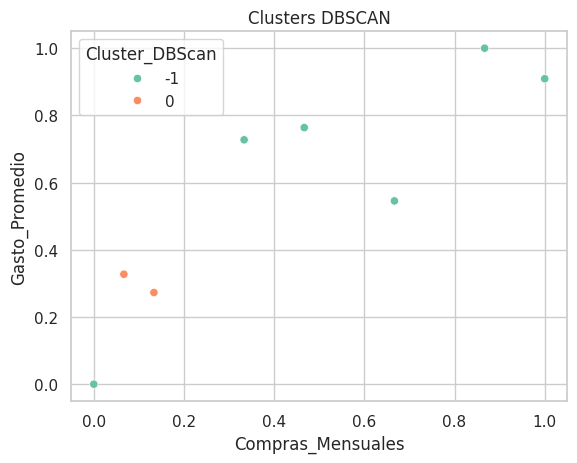

In [6]:
dbscan = DBSCAN(eps=0.3, min_samples=2)
df["Cluster_DBScan"] = dbscan.fit_predict(X)

sns.scatterplot(data=df, x="Compras_Mensuales", y="Gasto_Promedio", hue="Cluster_DBScan", palette="Set2")
plt.title("Clusters DBSCAN")
plt.show()

In [7]:
sil_kmeans = silhouette_score(X, df["Cluster_KMeans"])
dbi_kmeans = davies_bouldin_score(X, df["Cluster_KMeans"])

labels_dbscan = df["Cluster_DBScan"]
valid_labels = labels_dbscan[labels_dbscan != -1]

if valid_labels.nunique() >= 2:
    sil_dbscan = silhouette_score(X[labels_dbscan != -1], valid_labels)
    dbi_dbscan = davies_bouldin_score(X[labels_dbscan != -1], valid_labels)
else:
    sil_dbscan = "No válido"
    dbi_dbscan = "No válido"

print(f"Silhouette Score - KMeans: {sil_kmeans:.2f}")
print(f"Silhouette Score - DBSCAN: {sil_dbscan}")
print(f"Davies-Bouldin Index - KMeans: {dbi_kmeans:.2f}")
print(f"Davies-Bouldin Index - DBSCAN: {dbi_dbscan}")

Silhouette Score - KMeans: 0.36
Silhouette Score - DBSCAN: No válido
Davies-Bouldin Index - KMeans: 0.87
Davies-Bouldin Index - DBSCAN: No válido


### Conclusiones
- **KMeans** segmentó los clientes en 3 grupos con una calidad moderada (Silhouette = 0.36, Davies-Bouldin = 0.87).
- **DBSCAN** no encontró al menos 2 clusters válidos con `eps = 0.3`: con tan pocos datos y sin separación clara, puede fallar o marcar todo como ruido.
- Se validó el número de clusters antes de calcular las métricas para evitar errores en DBSCAN.